 ## Import Necessary Librares

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.naive_bayes import MultinomialNB
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics import confusion_matrix,classification_report,accuracy_score
from sklearn.preprocessing import LabelEncoder
import joblib

**loading Dataset**

In [2]:
text_mess=pd.read_csv("SPAM text message 20170820 - Data.csv")


**Data Cleaning And Inspection**

In [3]:
text_mess.head()

,Category,Message
0,ham,"Go until jurong point, crazy.. Available only ..."
1,ham,Ok lar... Joking wif u oni...
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...
3,ham,U dun say so early hor... U c already then say...
4,ham,"Nah I don't think he goes to usf, he lives aro..."


In [4]:
text_mess.shape

(5572, 2)

In [5]:
text_mess.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5572 entries, 0 to 5571
Data columns (total 2 columns):
 #   Column    Non-Null Count  Dtype 
---  ------    --------------  ----- 
 0   Category  5572 non-null   object
 1   Message   5572 non-null   object
dtypes: object(2)
memory usage: 87.2+ KB


In [6]:
text_mess.describe()

,Category,Message
count,5572,5572
unique,2,5157
top,ham,"Sorry, I'll call later"
freq,4825,30


In [7]:
text_mess.duplicated().sum()

np.int64(415)

In [8]:
text_mess.isnull().sum()

Category    0
Message     0
dtype: int64

In [9]:
text_mess=text_mess.drop_duplicates()

In [10]:
#check
text_mess.duplicated().sum()

np.int64(0)

In [11]:
text_mess.shape

(5157, 2)

**Feature Engineering**

In [12]:
text_mess['Message'] = text_mess['Message'].astype(str)

In [13]:
vectorizer = TfidfVectorizer(stop_words='english')  
x= vectorizer.fit_transform(text_mess["Message"])

In [14]:
encoder=LabelEncoder()
y=encoder.fit_transform(text_mess["Category"])

**Building and Training the MultinomialNB Model**

In [15]:
# 80% Training , 20% Test
x_train,x_test,y_train,y_test=train_test_split(x,y,test_size=0.2,random_state=42)

In [16]:
# MultinomialNB model
clf=MultinomialNB()
clf.fit(x_train,y_train)


,alpha,1.0
,force_alpha,True
,fit_prior,True
,class_prior,None


**Making Predictions and Evaluating the Model**

In [17]:
y_pred=clf.predict(x_test)

In [18]:
#Accuracy score 
acc_score=accuracy_score(y_test,y_pred)
print(f"Accuracy:{acc_score:.2}")

Accuracy:0.97


In [19]:
# Confusion Matrix
conf_matrix=confusion_matrix(y_test,y_pred)
print("confusion matrix:\n",conf_matrix)

confusion matrix:
 [[896   0]
 [ 32 104]]


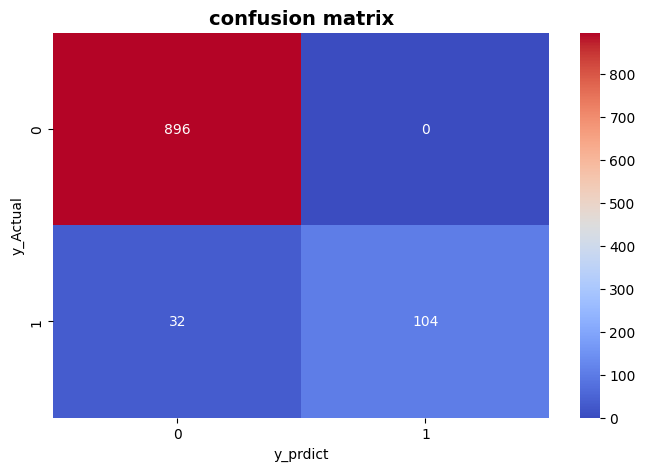

In [20]:
# Plot Confusion Matrix
plt.figure(figsize=(8,5))
sns.heatmap(conf_matrix,annot=True,fmt="d",cmap="coolwarm")
plt.xlabel("y_prdict")
plt.ylabel("y_Actual")
plt.title("confusion matrix",fontsize=14,fontweight="bold")
plt.show()

In [21]:
# Classification Report
class_report=classification_report(y_test,y_pred) 
print("classification report:\n",class_report)

classification report:
               precision    recall  f1-score   support

           0       0.97      1.00      0.98       896
           1       1.00      0.76      0.87       136

    accuracy                           0.97      1032
   macro avg       0.98      0.88      0.92      1032
weighted avg       0.97      0.97      0.97      1032



In [22]:
joblib.dump(clf, "spam_model.pkl")
joblib.dump(vectorizer, "vectorizer.pkl")
joblib.dump(encoder, "label_encoder.pkl")

['label_encoder.pkl']